In [ ]:
from pathlib import Path

import pandas as pd

data_path = Path("C:/Users/solli/Documents/YH utbildning/Python/Uppgift 1/health_study_dataset.csv")

# läsa in data filen, skapa en DataFrame
df = pd.read_csv(data_path)

print(f"Länk till datafilen: {data_path.resolve()}")

if not data_path.exists():
    raise FileNotFoundError(
        "Går inte att ta läsa in datafilen "
        "Kontrollera länken till datafilen!"
    )


print(f"Antal rader i datafilen: {df.shape[0]}")
print(f"Antal kolumner: {df.shape[1]}")

# visa endast fem första raderna
display(df.head())

Länk till datafilen: C:\Users\solli\Documents\YH utbildning\Python\Uppgift 1\health_study_dataset.csv
Länk till datafilen.

Antal rader i input filen: 800
Antal kolumner: 9


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## Kontollera data kvalitet

Ta fram/analysera datatyper för varje kolumn, 0 eller värden som inte finns med i kolumnen eller finns flera ggr (dubletter etc), vilka är kategoriska och binära

In [4]:
# visa tabellens kolumnnamn
column_names = df.columns.tolist()

print("Dataset innehåller följande kolumner:")

for column_name in column_names:
    print(f"- {column_name}")

Dataset innehåller följande kolumner:
- id
- age
- sex
- height
- weight
- systolic_bp
- cholesterol
- smoker
- disease


In [8]:
print("\nDatatyper i datafilen")
print("-----------------------")

# to_frame - lägger in resultat i tabell
data_types_table = df.dtypes.to_frame(
    name="Datatyp"
)

display(data_types_table)



Datatyper i datafilen
-----------------------


,Datatyp
id,int64
age,int64
sex,str
height,float64
weight,float64
systolic_bp,float64
cholesterol,float64
smoker,str
disease,int64


In [35]:
# Check för värden som inte finns med med isna som kan bli True eller False

m_values = df.isna().sum()

m_values_table = m_values.to_frame(
    name="Antal saknade värden"
)

if m_values.sum() > 0:
    print(
        f"Antal är"
        f"{m_values_sum()} "
        
    )
   
    display(m_values_sum())
    display(m_values_table)

else:
    print("Inga saknade värden")





Inga saknade värden


In [36]:

# Duplicerade rader


# Använder duplicated() - funktion som returnerar True eller false om rader är duplicerade
duplicates = df[df.duplicated()]

# Använder len() - funktion som räknar antalet duplicerade rader.
number_of_duplicates = len(duplicates)


if number_of_duplicates > 0:
    print(
        f"Antal duplicerade rader är "
        f"{number_of_duplicates} "
        
    )
    print("\nDuplicerade rader")
    display(duplicates)

else:
    print("Inga duplicerade rader")

Inga duplicerade rader


In [ ]:

# Kontrollera kategoriska och binära värden


# Använder unique fuktion som visar unika värden per kolumn
unique_gender = df["sex"].dropna().unique().tolist()
unique_smoker = df["smoker"].dropna().unique().tolist()
unique_disease = df["disease"].dropna().unique().tolist()

print(f"Unika värden i gender kolumn: {unique_gender}")
print(f"Unika värden i smoker kolumn: {unique_smoker}")
print(f"Unika värden i disease kolumn: {unique_disease}")



Unika värden i gender kolumn: ['F', 'M']
Unika värden i smoker kolumn: ['No', 'Yes']
Unika värden i disease: [0, 1]


### Sammanfattning av datakvalitet checken

Resultaten av första data analysen visar att finel har 800 rader med 9 kolumner samt att datakvalitet är hög: inga dubletter, alla värden finns och data behöver inte förbreddas extra heller ersättas.

Det finns 2 kategoriska variabler: `gender` och `smoker` och en binär variable `disease`.

## Beskrivande statistik

I den här avsnittet beräknas enligt uppgiften: medelvärde,median, minimum och maximum.

In [58]:

numeric_columns = [
    "age",
    "weight",
    "height",
    "systolic_bp",
    "cholesterol"
]

descriptive_calculation = (
    df[numeric_columns]
    .agg(["mean", "median", "min", "max"])
    .T  # byter rader och kolumner,   variabler = rader, statistikmått = kolumner
    .round(1) # Avrundar till 1 decimal
)

descriptive_calculation.columns = [
    "Medelvärde",
    "Median",
    "Minimum",
    "Maximum"
]

descriptive_calculation.index = [
    "Ålder (år)",
    "Vikt (kg)",
    "Längd (cm)",
    "Systoliskt blodtryck (mmHg)",
    "Kolesterol"
]

descriptive_calculation.index.name = "Variabel"

display(descriptive_calculation)

,Medelvärde,Median,Minimum,Maximum
Variabel,,,,
Ålder (år),49.4,50.0,18.0,90.0
Vikt (kg),73.4,73.2,33.7,114.4
Längd (cm),171.8,171.4,144.4,200.4
Systoliskt blodtryck (mmHg),149.2,149.4,106.8,185.9
Kolesterol,4.9,5.0,2.5,7.9


## Visualisering och grafer

I den här avsnittet skapas grafer för att visualisera datan:
1. Histogram och Kernel Density Estimation eller KDE-kurva används över systoliskt blodtryck - används för att visualisera antal personer inom varje blodtrycksintervall intervall 
2. Boxplot visar vikt skillnaden mellan kvinnor och män
3. Stapeldiagram - visar andel rökare vs andel icke-rökare
4. Histogram - åldersfördelning och cholesterol värden
5. Spridningsdiagram - ålder och blodtryck 
6. Boxplot - Sjukdomsandel och rökstatus

In [61]:
# Förbredda inför grafisk analys
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Färger för visualierings i grafer
BLUE = "steelblue"
DARK_BLUE = "darkblue"
RED = "firebrick"
GREEN = "mediumseagreen"
ORANGE = "darkorange"
PURPLE = "mediumpurple"

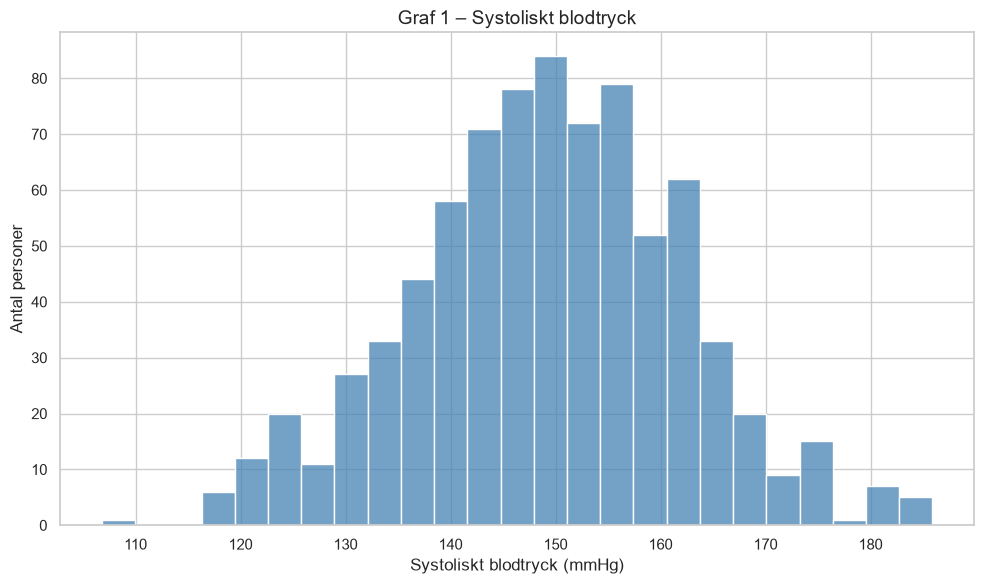

In [64]:
# Graf 1 – histogram över systoliskt blodtryck 
blood_pressure = df["systolic_bp"].dropna()

# Skapa en ny figur.
plt.figure(figsize=(10, 6))

sns.histplot(
    data=blood_pressure,
    bins=25,
    color=BLUE,
    edgecolor="white"
)

plt.title(
    "Graf 1 – Systoliskt blodtryck",
    fontsize=14
)

plt.xlabel(
    "Systoliskt blodtryck (mmHg)"
)

plt.ylabel(
    "Antal personer"
)

plt.tight_layout()
plt.show()

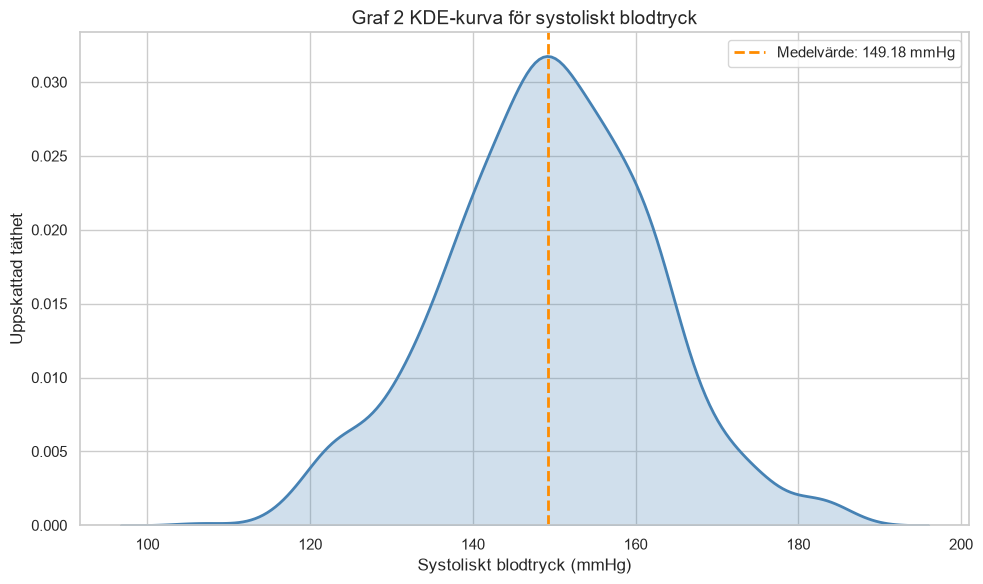

In [70]:
# Graf 2 – KDE-kurva för systoliskt blodtryck 
mean_blood_pressure = blood_pressure.mean()

plt.figure(figsize=(10, 6))

# KDE-kurvan 
sns.kdeplot(
    data=blood_pressure,
    fill=True,
    color=BLUE,
    linewidth=2
)


plt.axvline(
    mean_blood_pressure,
    color=ORANGE,
    linestyle="--",
    linewidth=2,
    label=f"Medelvärde: {mean_blood_pressure:.2f} mmHg"
)

plt.title(
    "Graf 2 KDE-kurva för systoliskt blodtryck",
    fontsize=14
)

plt.xlabel(
    "Systoliskt blodtryck (mmHg)"
)

plt.ylabel(
    "Uppskattad täthet"
)

plt.legend()
plt.tight_layout()
plt.show()

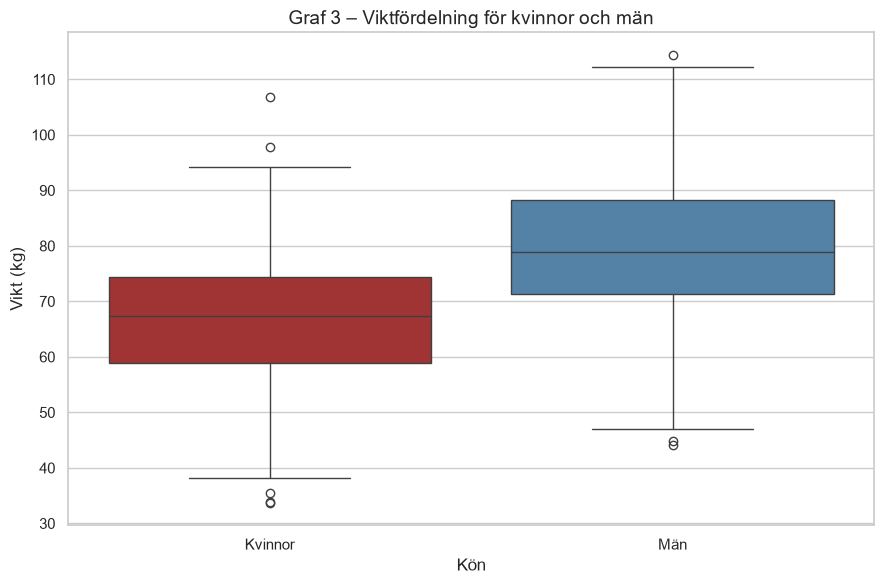

In [147]:
# Graf 3 – boxplot över vikt per kön

plt.figure(figsize=(9, 6))

# Boxploten för viktfördelning mellan kvinnor och män.
sns.boxplot(
    data=df,
    x="sex",
    y="weight",
    order=["F", "M"],
    hue="sex",
    palette={
        "F": RED,
        "M": BLUE
    },
    legend=False
)

plt.title(
    "Graf 3 – Viktfördelning för kvinnor och män",
    fontsize=14
)

plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")

# Byt F och M till svenska etiketter.
plt.xticks(
    ticks=[0, 1],
    labels=["Kvinnor", "Män"]
)

plt.tight_layout()
plt.show()

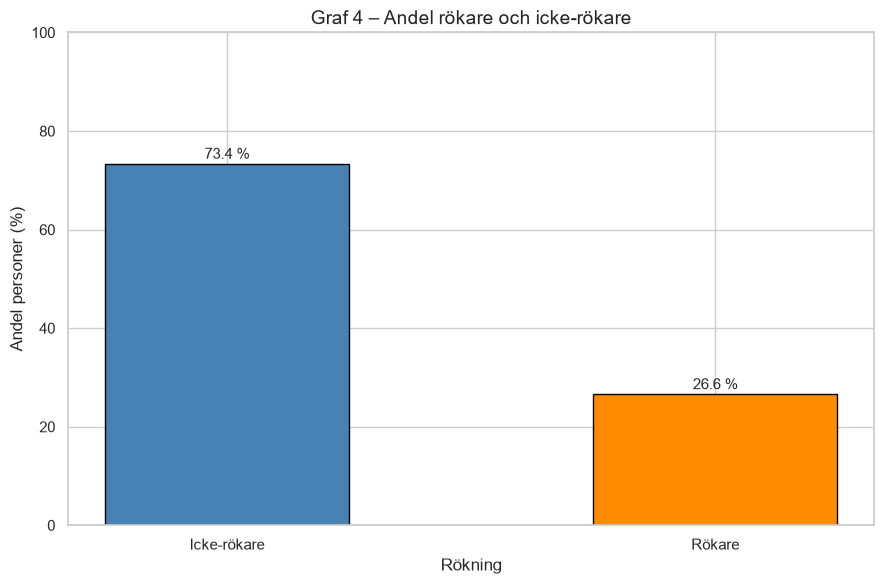

In [148]:
#Graf 4 – andel rökare och icke-rökare - procentuellt
smoker_percentage = (
    df["smoker"]
    .value_counts(normalize=True)
    .reindex(["No", "Yes"])
    .mul(100) #multiplicerar med 100 - ange procent värde 
)

# Svenska etiketter.
smoker_labels = [
    "Icke-rökare",
    "Rökare"
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    smoker_labels,
    smoker_percentage,
    color=[BLUE, ORANGE],
    edgecolor="black",
    width = 0.5
)

plt.title(
    "Graf 4 – Andel rökare och icke-rökare",
    fontsize=14
)

plt.xlabel("Rökning")
plt.ylabel("Andel personer (%)")
plt.ylim(0, 100)


for bar, percentage in zip(
    bars,
    smoker_percentage
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{percentage:.1f} %",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

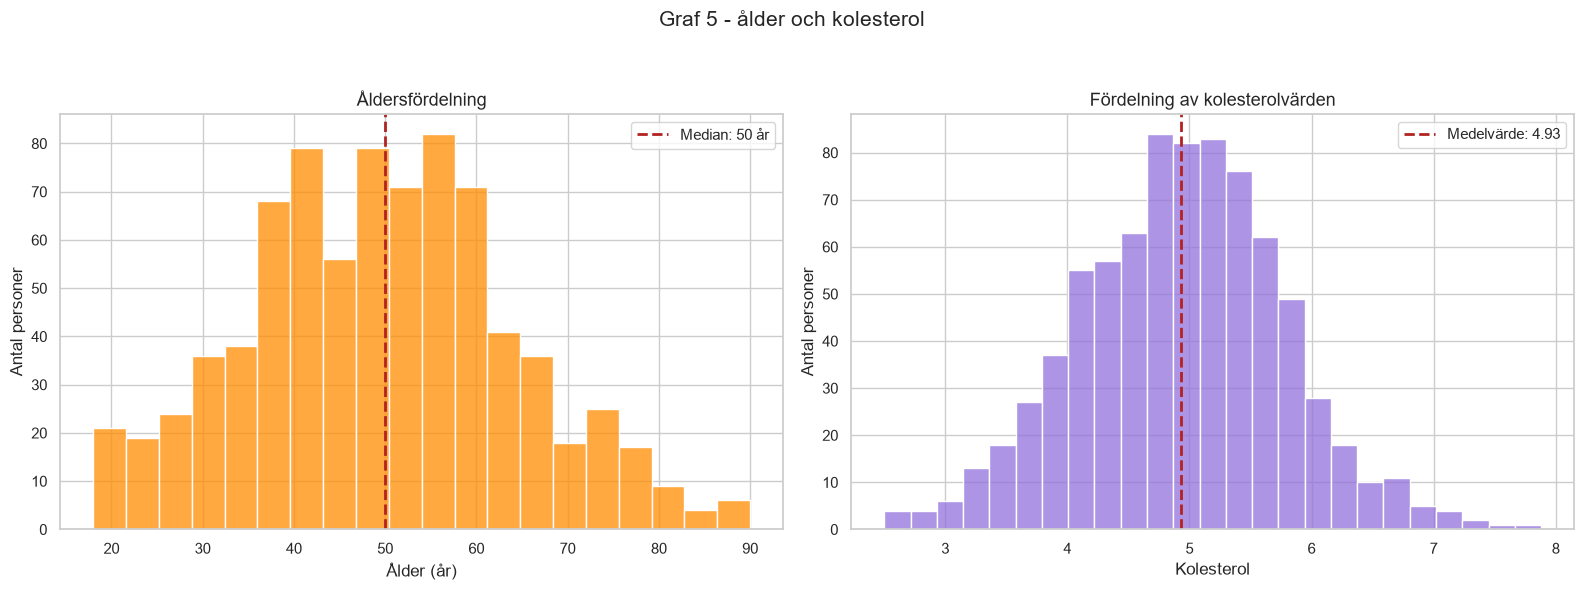

In [149]:
# Graf 5 – histogram för ålder och kolesterol
age_values = df["age"].dropna()
cholesterol_values = df["cholesterol"].dropna()

# Räkna median och medelvärde för ålder och kolesterol
median_age = age_values.median()
mean_cholesterol = cholesterol_values.mean()

# En kombo diagram skapas
figure, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 6)
)


# Vänster: åldersfördelning


sns.histplot(
    data=age_values,
    bins=20,
    color=ORANGE,
    edgecolor="white",
    ax=axes[0]
)

axes[0].axvline(
    median_age,
    color=RED,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_age:.0f} år"
)

axes[0].set_title(
    "Åldersfördelning",
    fontsize=13
)

axes[0].set_xlabel("Ålder (år)")
axes[0].set_ylabel("Antal personer")
axes[0].legend()


# Höger diagram: kolesterolfördelning


sns.histplot(
    data=cholesterol_values,
    bins=25,
    color=PURPLE,
    edgecolor="white",
    ax=axes[1]
)

axes[1].axvline(
    mean_cholesterol,
    color=RED,
    linestyle="--",
    linewidth=2,
    label=f"Medelvärde: {mean_cholesterol:.2f}"
)

axes[1].set_title(
    "Fördelning av kolesterolvärden",
    fontsize=13
)

axes[1].set_xlabel("Kolesterol")
axes[1].set_ylabel("Antal personer")
axes[1].legend()


# Skapa rubriken
figure.suptitle(
    "Graf 5 - ålder och kolesterol",
    fontsize=15
)

# skapa plats för rubriken innan diagrammen
plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.show()

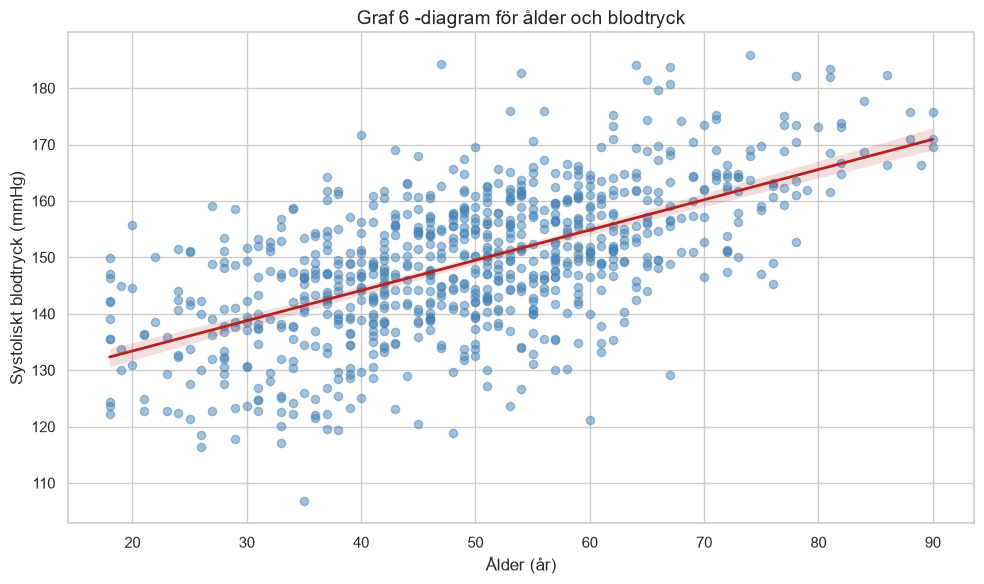

In [150]:
#Graf 6 – sålder vs blodtryck
plt.figure(figsize=(10, 6))

sns.regplot(  # här varje point representerar en person som formar en riktlinje för sambandet mellan ålder och blodtryck
    data=df,
    x="age",
    y="systolic_bp",
    scatter_kws={
        "alpha": 0.50,
        "s": 35,
        "color": BLUE
    },
    line_kws={
        "color": RED,
        "linewidth": 2
    }
)

plt.title(
    "Graf 6 -diagram för ålder och blodtryck",
    fontsize=14
)

plt.xlabel("Ålder (år)")
plt.ylabel("Systoliskt blodtryck (mmHg)")
plt.tight_layout()
plt.show()

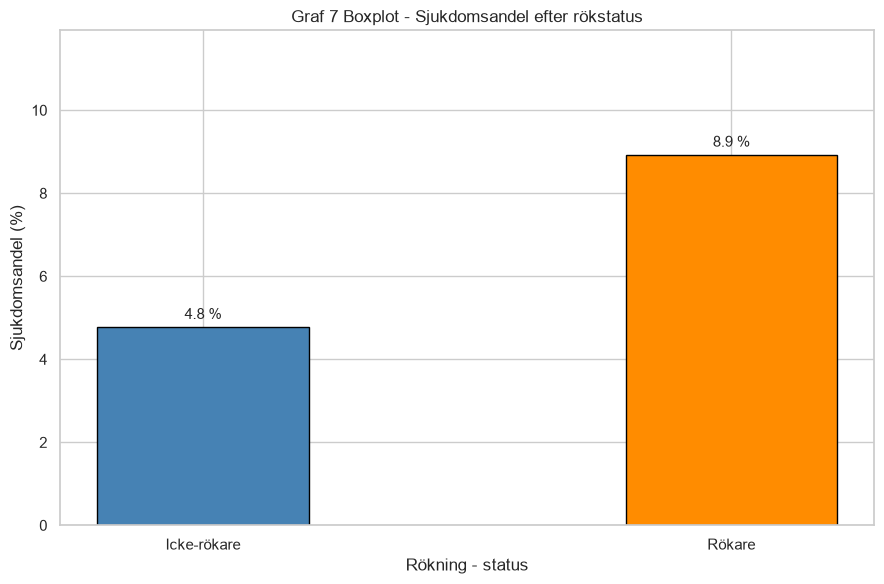

In [151]:
# Graf 7 – sjukdomsandel och rökstatus
# Medelvärdet inom varje grupp motsvarar därför andelen ettor.
disease_percentage_by_smoker = (
    df.groupby("smoker")["disease"]
    .mean()
    .reindex(["No", "Yes"])
    .mul(100)
)

smoker_labels = [
    "Icke-rökare",
    "Rökare"
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    smoker_labels,
    disease_percentage_by_smoker,
    color=[BLUE, ORANGE],
    edgecolor="black",
    width = 0.4
)

plt.title(
    "Graf 7 Boxplot - Sjukdomsandel efter rökstatus",
    fontsize=12
)

plt.xlabel("Rökning - status")
plt.ylabel("Sjukdomsandel (%)")


upper_limit = disease_percentage_by_smoker.max() + 3
plt.ylim(0, upper_limit)

# Visa procentvärdet ovanför varje stapel.
for bar, percentage in zip(
    bars,
    disease_percentage_by_smoker
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{percentage:.1f} %",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

## Sammanfattning av grafer och visualisering

För Histogrammet och KDE-kurvan, resultatet indikerar at blodtryket är fördelat runt 150mmHg. Stapeldiagrammet för
rökstatus visar att andelen icke-rökare är större än röckare. Den kombinerade ålders och kolesterolfördelningen diagram visar två separata
histogram - där en har median för ålder och den andra medel värde för kolesterol.
Spridningsdiagrammet visar hur sambandet mellan ökningen av systoliskt och ålder. Sjukdomsandelen mellan rökare och
icke-rökare visar större siffor hos rökare.

Visualiseringarna indikerar några mönster i datan som kan användas som grund för fortsätt analys.

## Simulering 
Simulering kopplad till caset (med numphy och dataseed)
- Beräkna andelen personer i datasetet som har sjukdomen.
- Använd numpy för att simulera 1000 slumpade personer med samma sannolikhet för sjukdom.
- Jämför den simulerade andelen med den verkliga andelen i datasetet.

Varför använda seed? - för att återskapa simulering, utan seed - random resultat

In [152]:

#Beräkning av sjukdomsandel i datasetet

total_antal = len(df)
antal_disease = df["disease"].sum()

antal_mean = df["disease"].mean() *100


print(
    f"Antal personer i ursprunglig dataset: "
    f"{total_antal}"
)

print(
    f"Antal personer med sjukdom: "
    f"{antal_disease}"
)

print(
    f"Sjukdomsandel: "
    f"{antal_mean:.2f} %"
)

Antal personer i ursprunglig dataset: 800
Antal personer med sjukdom: 47
Sjukdomsandel: 5.88 %


In [153]:
# SIMULERING

# Först beräkna sjukdomsandelen som binär variabel.
observerad_andel = df["disease"].mean()

antal_simulerade = 1000 # enligt uppgiften är det 1000 personer

random_seed = 2026 # sätter värdet för seed för att få samma resultat varje gång simuleringen körs
#2026 är ett tal som inte påverkar resultatet, det kan vara vilket tal som helst.

# Nu skapas en slumpgenerator 
simulator = np.random.default_rng(random_seed)

# n=1 ett utfall per person (1 eller 0 - sjuk eller inte sjuk)
# p - sannolikheten för sjukdom
# size - antalet simulerade personer
simulation = simulator.binomial(
    n=1,
    p=observerad_andel,
    size=antal_simulerade
)
simulerat_antal_sjuka = simulation.sum()

simulerad_andel = simulation.mean()
simulerad_procent = simulerad_andel * 100
observerad_procent = observerad_andel * 100

# Skriv ut resultaten.
print(f"Antal simulerade personer: {antal_simulerade}")
print(f"Simulerat antal personer med sjukdom: {simulerat_antal_sjuka}")
print(f"Observerad sjukdomsandel: {observerad_procent:.2f} %")
print(f"Simulerad sjukdomsandel: {simulerad_procent:.2f} %")

Antal simulerade personer: 1000
Simulerat antal personer med sjukdom: 63
Observerad sjukdomsandel: 5.88 %
Simulerad sjukdomsandel: 6.30 %


### Analys av simuleringen


Simuleringen på 1000 personer gav resultat med att 63 personer med sjukdomen (6,3 %)

Medan observerad sjukdomsandel i datasätet var det 47 av 800 personer med sjukdomen - (5,88 %)

6,30 - 5,88 = 0,42 - liten mellanskillnad - simuleringen är nära observationen

## Konfidensintervall 

I den här kapitel används ett konfidensintervall på 95% för normal approximation

Tre metoder använd för beräkning av konfidensintervallet_

1. normalapproximation,
2. t-intervall,
3. bootstrap

Standardavvikelsen beskriver variationen mellan personernas individuella
blodtrycksvärden. Standardfelet beskriver i stället osäkerheten i det
beräknade medelvärdet.

Standardfelet beräknas med:

\[
SE=\frac{s}{\sqrt{n}}
\]

där \(s\) är stickprovets standardavvikelse och \(n\) är antalet observationer.

In [154]:
# Förbredd dataBlodtrycksvärden 
blodtryck = df["systolic_bp"].dropna()

antal = len(blodtryck)
medel = blodtryck.mean()
standardfel = stats.sem(blodtryck)

print(f"Antal observationer: {antal}")
print(f"Medelblodtryck: {medel:.2f} mmHg")
print(f"Standardfel: {standardfel:.3f} mmHg")

Antal observationer: 800
Medelblodtryck: 149.18 mmHg
Standardfel: 0.452 mmHg


## Varför behövs standardavvikelse och standardfel?

Standardavvikelsen - beskriver avvikelse från medelvärdet eller osäkerhet - en större elle mindre nivåer.

I datasetet - medel avvivelse är 12,79 mmHg.

Standardfelet beskriver osäkerheten i det beräknade medelvärdet, det minskar när storlek på observationen pull ökar. 



In [155]:
#Standard avvikelse och standardfel beräknas med numpy och scipy.stats

blodtryck = df["systolic_bp"].dropna().to_numpy()

# Grundläggande värden.
antal = len(blodtryck)
medel = blodtryck.mean()

# ddof=1 - avviellse
standardavvikelse = blodtryck.std(ddof=1)

standardfel = standardavvikelse / np.sqrt(antal)


print(f"Standardavvikelse: {standardavvikelse:.2f} mmHg")
print(f"Standardfel: {standardfel:.3f} mmHg")



Standardavvikelse: 12.79 mmHg
Standardfel: 0.452 mmHg


### Resultat av standardavvikelse och standardfel

Standardavvikelsen - beskriver olika värden hos deltagarnas enskilda blodtrycksvärden.
Bldtrycket vanligtvis varierar med  crika 12,79 mmHg och standrdfel är 0,452 mmHg det kan förklaras med.
Standardavvikelsen är variationen mellan personer - 12,70mmHg i detta fallet. 

Standardfelet 0.452 mmHg - osäkerhetsnivån i medelvärdet. Standardfelet används också inom uträkningar av konfidensintervallet. 



In [156]:
# Metod 1 – Normalapproximation  med z-värdet 1,96 för ett 95-procentigt konfidensintervall

z = 1.96 # 1,96 kritisk z-värdet 

normal_nedre = medel - z * standardfel
normal_ovre = medel + z * standardfel

print(
    f"Normalapproximation: "
    f"{normal_nedre:.2f}–{normal_ovre:.2f} mmHg"
)

Normalapproximation: 148.29–150.07 mmHg


In [157]:
# Metod 2 – t-intervall - beräkna konfidensintervall med t-fördelningen

frihetsgrader = antal - 1 # Frihetsgrader räknas som antal graderminus 1.

# Kritiskt t-värde för ett 95-procentigt intervall.
t_varde = stats.t.ppf(
    0.975,
    df=frihetsgrader
)

t_nedre = medel - t_varde * standardfel
t_ovre = medel + t_varde * standardfel

print(
    f"t-intervall: "
    f"{t_nedre:.2f}–{t_ovre:.2f} mmHg"
)

t-intervall: 148.29–150.07 mmHg


In [158]:
# Metod 3 Bootstrap – för 95% konfidensintervall för medelvärdet av blodtryck
antal_bootstrap = 10000


bootstrap_rng = np.random.default_rng(2026)
# Tom array för bootstrap
bootstrap_medel = np.empty(antal_bootstrap)

# 10 000 stickprov 
for i in range(antal_bootstrap):
    bootstrap_stickprov = bootstrap_rng.choice(
        blodtryck,
        size=antal,
        replace=True
    )

    bootstrap_medel[i] = (
        bootstrap_stickprov.mean()
    )

bootstrap_nedre, bootstrap_ovre = np.percentile(
    bootstrap_medel,
    [2.5, 97.5]
)

print(
    f"Bootstrapintervall: "
    f"{bootstrap_nedre:.2f}–{bootstrap_ovre:.2f} mmHg"
)

Bootstrapintervall: 148.29–150.07 mmHg


In [159]:

#Sammanställning av konfidensintervall i en tabell
intervall_tabell = pd.DataFrame({
    "Metod": [
        "Normalapproximation",
        "t-intervall",
        "Bootstrap"
    ],
    "Nedre gräns (mmHg)": [
        normal_nedre,
        t_nedre,
        bootstrap_nedre
    ],
    "Övre gräns (mmHg)": [
        normal_ovre,
        t_ovre,
        bootstrap_ovre
    ]
})

intervall_tabell[
    ["Nedre gräns (mmHg)", "Övre gräns (mmHg)"]
] = intervall_tabell[
    ["Nedre gräns (mmHg)", "Övre gräns (mmHg)"]
].round(2)

display(intervall_tabell)

,Metod,Nedre gräns (mmHg),Övre gräns (mmHg)
0,Normalapproximation,148.29,150.07
1,t-intervall,148.29,150.07
2,Bootstrap,148.29,150.07


## Resultat och analys av konfidensintervallen

Samtliga tre metoder gav liknande utfall för det genomsnittliga blodtrycket - 148,29 - 150,07 mmHg.

### Normalapproximation

Här z på 1,96 används för beräkningar och med styckprovet på 800 personer bli fördelning symmetrisk.

### t-intervall

t-intervallet visar fördelningen bli mer normalfördelningen.

### Bootstrapintervall

Bootstrapmetoden bygger på styckprov och visar också liknande resultat.


### Slutsats

De tre metoderna fungerar och ger liknande resultat där t-intervallet och normal approximationen kompletterar varandra och även 
och bootstrapmetoden. Det kan beror på 800 observationer är tillräkliga och med flera observationer kan bli även mer lika.

## Hypotesprövning

- Nollhypotes, H₀: Rökare har inte högre genomsnittligt systoliskt blodtryck än icke-rökare.
- H₁, alternativ: Rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

Ett ensidigt Welch t-test skulle passa här för att jämföra 2 oberoende grupper - rökare och icke röckare. 
Welch-testet används för grupper med varierande antal deltagare vilket passar den här uppgiften (Delacre et al., 2019).

Signifikansnivån är 0,05 eller 5% risk på 5% för  I-fel ska accepteras samt nollhypotesen kastas - det är vanligt att avända 0.05 nivån i utvärderingar av hypotes (NIST, u.å.). Detta innebär - . Om p-värdet är mindre än 0,05 förkastas nollhypotesen.

In [160]:
# Hypotesprövning – jämförelse av medelvärden mellan rökare och icke-rökare
rokare = df.loc[
    df["smoker"] == "Yes",
    "systolic_bp"
].dropna()

icke_rokare = df.loc[
    df["smoker"] == "No",
    "systolic_bp"
].dropna()

# Medelvärden:
medel_rokare = rokare.mean()
medel_icke_rokare = icke_rokare.mean()

skillnad = medel_rokare - medel_icke_rokare


standardfel_skillnad = np.sqrt(
    rokare.var(ddof=1) / len(rokare)
    + icke_rokare.var(ddof=1) / len(icke_rokare)
)

# Welch t-test för rökare och icke-rlkare
testresultat = stats.ttest_ind(
    rokare,
    icke_rokare,
    equal_var=False,
    alternative="greater"
)

print(f"Antal rökare: {len(rokare)}")
print(f"Antal icke-rökare: {len(icke_rokare)}")
print(f"Medelvärde för rökare: {medel_rokare:.2f} mmHg")
print(f"Medelvärde för icke-rökare: {medel_icke_rokare:.2f} mmHg")
print(f"Observerad skillnad: {skillnad:.2f} mmHg")
print(f"Standardfel för skillnaden: {standardfel_skillnad:.3f} mmHg")
print(f"t-värde: {testresultat.statistic:.3f}")
print(f"p-värde: {testresultat.pvalue:.3f}")

if testresultat.pvalue < 0.05:
    print("Nollhypotesen funkar inte")
    print("N.")
else:
    print("Nollhypotesen kan inte förkastas.")
    print("Det finns inte tillräckligt stöd för att rökare har högre medelblodtryck.")

Antal rökare: 213
Antal icke-rökare: 587
Medelvärde för rökare: 149.52 mmHg
Medelvärde för icke-rökare: 149.05 mmHg
Observerad skillnad: 0.47 mmHg
Standardfel för skillnaden: 1.048 mmHg
t-värde: 0.450
p-värde: 0.326
Nollhypotesen kan inte förkastas.
Det finns inte tillräckligt stöd för att rökare har högre medelblodtryck.


In [ ]:
### Resultat 

Resultaten beräkningar visar att blodtryck hos röckare i genomsnitt är 149,52 mmHg, medan icke-rökarna hade ett genomsnitt på cirka
149,05 mmHg.

Resultat av Welch t-testet : p 0,326 vilket är högre än signifikansnivån 0,05 därmed Nollhypotesen kan inte förkastas 
menar att det är fortfarande möjligt att rökare och icke-rökare har samma medelblodtryck.

Detta inebbar att analysen inte tillräckligt för att dra slutsater statistiskt grundad. 



## Simulering av testets power

Power kan förklaras som sannolikheten att upptäcka en verklig
effekt när effekten faktiskt finns.

Antagande: Verklig skillnad i blodtrycket mellan rökare och icke-rökare är 5 mmHg.

Antal simuleringar sätts till t.ex 2 000 gånger.
p-värdet bör vara mindre än 0,05 (Lakens, 2022).

In [166]:
# Powersimulering med Welch t-testet

import numpy as np
from scipy import stats


antal_simuleringar = 2000
antal_personer_per_grupp = 100

# Antagande verklig skillnad mellan grupperna.
verklig_skillnad = 5

# Antagande standardavvikelse.
standardavvikelse = 15

# Signifikansnivå.
signifikansniva = 0.05

# Seed gör att vi får samma resultat vid varje körning.
rng_power = np.random.default_rng(2026)

# Räknar simuleringar som ger p < 0.05.
antal_signifikanta_resultat = 0


# Upprepa simuleringen 2 000 gånger.
for _ in range(antal_simuleringar):

    # Simulera blodtryck
    simulerade_icke_rokare = rng_power.normal(
        loc=145,
        scale=standardavvikelse,
        size=antal_personer_per_grupp
    )

    # Simulera blodtryck där Medelvärdet är 5 mmHg högre.
    simulerade_rokare = rng_power.normal(
        loc=145 + verklig_skillnad,
        scale=standardavvikelse,
        size=antal_personer_per_grupp
    )

    # Welch t-test.
    simulerat_test = stats.ttest_ind(
        simulerade_rokare,
        simulerade_icke_rokare,
        equal_var=False
    )

    # p-värdet ändra till ett ensidigt p-värde.
    if simulerat_test.statistic > 0:
        ensidigt_p_varde = simulerat_test.pvalue / 2
    else:
        ensidigt_p_varde = 1 - simulerat_test.pvalue / 2

    # Simuleringen om p-värdet är under 0.05.
    if ensidigt_p_varde < signifikansniva:
        antal_signifikanta_resultat += 1


power = antal_signifikanta_resultat / antal_simuleringar


print(f"Antal simuleringar: {antal_simuleringar}")
print(f"Antal personer per grupp: {antal_personer_per_grupp}")
print(f"Verklig simulerad skillnad: {verklig_skillnad} mmHg")
print(f"Signifikanta resultat: {antal_signifikanta_resultat}")
print(f"Uppskattad power: {power:.1%}")

Antal simuleringar: 2000
Antal personer per grupp: 100
Verklig simulerad skillnad: 5 mmHg
Signifikanta resultat: 1522
Uppskattad power: 76.1%


## Sammanfattande analys

### Tolkning av power

Power kalkylerad till 76,1% - testet upptäckte skillnaden i ungefär 76 procent av de simulerade experimenten.

100-76,1 = 23,9 % - detta innebär att i 23,9% upptäckte testet inte skillnaden

Powerresultatet 76,1% beror på effektstorlek, standardavvikelse, signifikansnivå och större stickprovsstorlek ger högre
power (Lakens, 2022).


### Hypotesprövning

P-värde på cirka 0,326 - resultat av den ensidiga Welch t-testet - p.

Welch t-test passar till syftet av labber eftersom han har två oberoende grupper (Delacre et al., 2019).

Normalapproximation, t-intervall och percentile-bootstrap -  användes konfidensintervallet: 


## Referenslista

Delacre, M., Leys, C., Mora, Y. L. & Lakens, D. (2019).
*Taking parametric assumptions seriously: Arguments for the use of
Welch’s F-test instead of the classical F-test in one-way ANOVA*.
International Review of Social Psychology, 32(1).
https://doi.org/10.5334/irsp.198

Lakens, D. (2022).
*Sample size justification*.
Collabra: Psychology, 8(1), 33267.
https://doi.org/10.1525/collabra.33267

National Institute of Standards and Technology, NIST (u.å.).
*Critical values and p-values*.
https://www.itl.nist.gov/div898/handbook/prc/section1/prc131.htm
Hämtad 23 november 2026.